# EDA Hortikultura Sayur per Kecamatan — Kabupaten Kediri

Tujuan: memahami data **luas panen** dan **produksi** sayuran per kecamatan, lalu menyiapkannya untuk **pemodelan prediksi produksi/luas panen** (fitur Prediksi, Maps, dan Clustering di AgriDash).

Data sudah dibersihkan oleh tim, jadi notebook ini fokus ke: cek ulang cepat → EDA → cek kesiapan untuk model.

| File | Isi |
|---|---|
| `luas_panen_hortikultura_sayur_per_kecamatan.csv` | luas panen per kecamatan × komoditas (+ kolom satuan) |
| `produksi_hortikultura_sayur_per_kecamatan.csv` | produksi (kuintal) per kecamatan × komoditas |

**Cara pakai:** simpan notebook di folder `notebooks/`. File CSV boleh di folder mana saja di dalam `data/` (dicari otomatis).

## 1. Setup & Lokasi Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def cari_project_root(start_path=None):
    start = os.path.abspath(start_path or os.getcwd())
    current = start

    while True:
        if (
            os.path.isdir(os.path.join(current, "data"))
            and (
                os.path.isdir(os.path.join(current, "notebooks"))
                or os.path.isdir(os.path.join(current, ".git"))
            )
        ):
            return current

        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent

    return os.path.abspath(os.path.join(start, ".."))


PROJECT_ROOT = cari_project_root()
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

# folder tempat file hasil cleaning (kalau beda, tidak masalah: file dicari otomatis di seluruh data/)
FOLDER_HORTI = os.path.join(DATA_DIR, "clean", "hortikultura")
# hasil olahan notebook ini
OUT_HORTI = os.path.join(DATA_DIR, "processed", "hortikultura")
os.makedirs(OUT_HORTI, exist_ok=True)


def cari_file(nama_file, folder_utama):
    langsung = os.path.join(folder_utama, nama_file)
    if os.path.isfile(langsung):
        return langsung
    ketemu = []
    for root, _, files in os.walk(DATA_DIR):
        if nama_file in files:
            ketemu.append(os.path.join(root, nama_file))
    if not ketemu:
        raise FileNotFoundError(f"'{nama_file}' tidak ditemukan di dalam {DATA_DIR}")
    ketemu.sort(key=lambda p: ("clean" not in p.lower(), p))      # utamakan folder 'clean'
    if len(ketemu) > 1:
        print(f"Ada {len(ketemu)} file bernama {nama_file}: {ketemu} -> dipakai yang pertama")
    return ketemu[0]


print("PROJECT ROOT :", PROJECT_ROOT)
print("DATA DIR     :", DATA_DIR)
print("OUTPUT       :", OUT_HORTI)

PROJECT ROOT : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1
DATA DIR     : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data
OUTPUT       : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\processed\hortikultura


## 2. Muat Data

In [2]:
def baca_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = df.columns.str.strip().str.lower()
    return df


F_LUAS = cari_file("luas_panen_hortikultura_sayur_per_kecamatan.csv", FOLDER_HORTI)
F_PROD = cari_file("produksi_hortikultura_sayur_per_kecamatan.csv", FOLDER_HORTI)
print("luas     <-", F_LUAS)
print("produksi <-", F_PROD, "\n")

luas_raw = baca_csv(F_LUAS)
prod_raw = baca_csv(F_PROD)

# pemeriksaan kolom: kalau ada yang kurang, pesan error menampilkan kolom aslinya
WAJIB = {
    "luas":     (luas_raw, ["kecamatan", "komoditas", "luas_panen", "satuan"]),
    "produksi": (prod_raw, ["kecamatan", "komoditas", "produksi_kuintal"]),
}
masalah = [f"{k}: tidak ada {[c for c in w if c not in df.columns]} | kolom: {df.columns.tolist()}"
           for k, (df, w) in WAJIB.items() if any(c not in df.columns for c in w)]
if masalah:
    raise ValueError("Kolom tidak sesuai:\n  " + "\n  ".join(masalah))

print("luas     :", luas_raw.shape, "| kolom:", luas_raw.columns.tolist())
print("produksi :", prod_raw.shape, "| kolom:", prod_raw.columns.tolist())
display(luas_raw.head())
display(prod_raw.head())

luas     <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\hortikultura\luas_panen_hortikultura_sayur_per_kecamatan.csv
produksi <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\hortikultura\produksi_hortikultura_sayur_per_kecamatan.csv 

luas     : (676, 4) | kolom: ['kecamatan', 'komoditas', 'luas_panen', 'satuan']
produksi : (676, 3) | kolom: ['kecamatan', 'komoditas', 'produksi_kuintal']


,kecamatan,komoditas,luas_panen,satuan
0,Mojo,Bawang Daun,0.00,Ha
1,Semen,Bawang Daun,0.00,Ha
2,Ngadiluwih,Bawang Daun,4.00,Ha
3,Kras,Bawang Daun,0.00,Ha
4,Ringinrejo,Bawang Daun,0.00,Ha


,kecamatan,komoditas,produksi_kuintal
0,Mojo,Bawang Daun,0.00
1,Semen,Bawang Daun,0.00
2,Ngadiluwih,Bawang Daun,290.00
3,Kras,Bawang Daun,0.00
4,Ringinrejo,Bawang Daun,0.00


## 3. Cek Kualitas Data (cek ulang cepat)

In [3]:
for nama, df in [("luas", luas_raw), ("produksi", prod_raw)]:
    print(f"=== {nama} ===")
    print("baris:", len(df), "| kecamatan:", df["kecamatan"].nunique(), "| komoditas:", df["komoditas"].nunique())
    print("nilai kosong:", int(df.isna().sum().sum()), "| duplikat (kecamatan+komoditas):", int(df.duplicated(["kecamatan", "komoditas"]).sum()))

print("\nAda kolom tahun/periode?", any(c in luas_raw.columns or c in prod_raw.columns for c in ["tahun", "periode", "bulan"]))
print("Kecamatan sama di kedua file?", set(luas_raw["kecamatan"].str.strip()) == set(prod_raw["kecamatan"].str.strip()))
beda = sorted(set(luas_raw["komoditas"].str.strip()) ^ set(prod_raw["komoditas"].str.strip()))
print("Nama komoditas yang penulisannya beda antar file:", beda)

=== luas ===
baris: 676 | kecamatan: 26 | komoditas: 26
nilai kosong: 0 | duplikat (kecamatan+komoditas): 0
=== produksi ===
baris: 676 | kecamatan: 26 | komoditas: 26
nilai kosong: 0 | duplikat (kecamatan+komoditas): 0

Ada kolom tahun/periode? False
Kecamatan sama di kedua file? True
Nama komoditas yang penulisannya beda antar file: ['Jamur Tiram', 'Jamur tiram']


In [4]:
# Satuan luas per komoditas
display(luas_raw.groupby("satuan")["komoditas"].unique().apply(sorted))

# Berapa banyak nilai 0?  Apakah luas = 0 selalu bersamaan dengan produksi = 0?
cek = luas_raw.merge(prod_raw.assign(komoditas=prod_raw["komoditas"].str.lower()),
                     left_on=["kecamatan", luas_raw["komoditas"].str.lower()],
                     right_on=["kecamatan", "komoditas"], how="inner", suffixes=("", "_p"))
print("Baris luas = 0     :", int((luas_raw["luas_panen"] == 0).sum()), "dari", len(luas_raw))
print("Baris produksi = 0 :", int((prod_raw["produksi_kuintal"] == 0).sum()), "dari", len(prod_raw))
display(pd.crosstab(cek["luas_panen"] > 0, cek["produksi_kuintal"] > 0, rownames=["luas > 0"], colnames=["produksi > 0"]))

satuan
Ha    [Bawang Daun, Bawang Merah, Bawang Putih, Baya...
M2                        [Jamur Lainnya, Jamur Merang]
Name: komoditas, dtype: object

Baris luas = 0     : 489 dari 676
Baris produksi = 0 : 489 dari 676


produksi > 0,False,True
luas > 0,,
False,489,0
True,0,187


**Temuan:**
- Kedua file rapi: tidak ada nilai kosong atau duplikat, dan sama-sama 26 kecamatan × 26 komoditas = 676 baris.
- **Nama komoditas beda huruf besar/kecil** antar file (`Jamur tiram` vs `Jamur Tiram`). Kalau digabung langsung, baris jamur tiram akan hilang. Disamakan di langkah berikutnya.
- **Satuan luas campuran:** hampir semua `Ha`, tapi Jamur Merang dan Jamur Lainnya `M2` (keduanya nol semua).
- **Nilai 0 = tidak ada panen/tidak tercatat, bukan data hilang.** Luas = 0 selalu bersamaan dengan produksi = 0. Jadi baris yang benar-benar berisi hanya sebagian kecil.
- **Produksi dalam kuintal** (1 kuintal = 100 kg).
- **Tidak ada kolom tahun/periode** → data satu periode saja (penting untuk jenis model yang bisa dibuat).

## 4. Persiapan Data

Langkah: samakan nama komoditas → gabungkan luas + produksi → satuan luas ke **hektar** → produksi ke **ton** → tandai baris yang ada datanya → hitung produktivitas.

Jamur dipisah sebagai kelompok sendiri karena budidayanya tidak berbasis lahan (satuan luasnya tidak sebanding dengan sayuran lain).

In [5]:
def kunci(s):
    return s.astype(str).str.strip().str.lower()

luas = luas_raw.copy()
prod = prod_raw.copy()
luas["kecamatan"] = luas["kecamatan"].astype(str).str.strip()
prod["kecamatan"] = prod["kecamatan"].astype(str).str.strip()
luas["kunci"] = kunci(luas["komoditas"])
prod["kunci"] = kunci(prod["komoditas"])

# nama baku komoditas diambil dari file produksi
nama_baku = prod.drop_duplicates("kunci").set_index("kunci")["komoditas"].astype(str).str.strip()

df = luas.merge(prod[["kecamatan", "kunci", "produksi_kuintal"]], on=["kecamatan", "kunci"],
                how="outer", validate="1:1", indicator=True)
assert (df["_merge"] == "both").all(), "Ada baris yang tidak punya pasangan antara file luas dan produksi"

df["komoditas"] = df["kunci"].map(nama_baku)
df["satuan"] = df["satuan"].astype(str).str.strip()
df["luas_ha"] = np.where(df["satuan"].str.lower() == "m2", df["luas_panen"] / 10_000, df["luas_panen"])
df["produksi_ton"] = df["produksi_kuintal"] / 10

df["ada_data"] = (df["luas_ha"] > 0) & (df["produksi_kuintal"] > 0)
df["kelompok"] = np.where(df["komoditas"].str.lower().str.startswith("jamur"), "Jamur", "Sayuran")

# produktivitas (kuintal/ha) hanya untuk sayuran yang ada datanya
df["produktivitas_ku_ha"] = np.where(df["ada_data"] & (df["kelompok"] == "Sayuran"),
                                     df["produksi_kuintal"] / df["luas_ha"], np.nan)

kolom_final = ["kecamatan", "komoditas", "kelompok", "luas_panen", "satuan", "luas_ha",
               "produksi_kuintal", "produksi_ton", "ada_data", "produktivitas_ku_ha"]
df = df[kolom_final].sort_values(["komoditas", "kecamatan"]).reset_index(drop=True)

d = df[df["ada_data"]].copy()                       # hanya baris yang ada datanya
sayur = d[d["kelompok"] == "Sayuran"].copy()        # sayuran saja (untuk luas & produktivitas)

print(f"Tabel gabungan : {df.shape[0]} baris  ({df['kecamatan'].nunique()} kecamatan x {df['komoditas'].nunique()} komoditas)")
print(f"Ada data       : {len(d)} baris ({len(d)/len(df):.1%})  | sayuran: {len(sayur)} | jamur: {len(d) - len(sayur)}")
df.head(8)

Tabel gabungan : 676 baris  (26 kecamatan x 26 komoditas)
Ada data       : 187 baris (27.7%)  | sayuran: 180 | jamur: 7


,kecamatan,komoditas,kelompok,luas_panen,satuan,luas_ha,produksi_kuintal,produksi_ton,ada_data,produktivitas_ku_ha
0,Badas,Bawang Daun,Sayuran,0.00,Ha,0.00,0.00,0.00,False,NaN
1,Banyakan,Bawang Daun,Sayuran,0.00,Ha,0.00,0.00,0.00,False,NaN
2,Gampengrejo,Bawang Daun,Sayuran,0.00,Ha,0.00,0.00,0.00,False,NaN
3,Grogol,Bawang Daun,Sayuran,0.00,Ha,0.00,0.00,0.00,False,NaN
4,Gurah,Bawang Daun,Sayuran,0.00,Ha,0.00,0.00,0.00,False,NaN
5,Kandangan,Bawang Daun,Sayuran,9.00,Ha,9.00,614.00,61.40,True,68.22
6,Kandat,Bawang Daun,Sayuran,10.50,Ha,10.50,909.00,90.90,True,86.57
7,Kayenkidul,Bawang Daun,Sayuran,2.00,Ha,2.00,140.00,14.00,True,70.00


## 5. EDA

### 5.1 Ketersediaan data

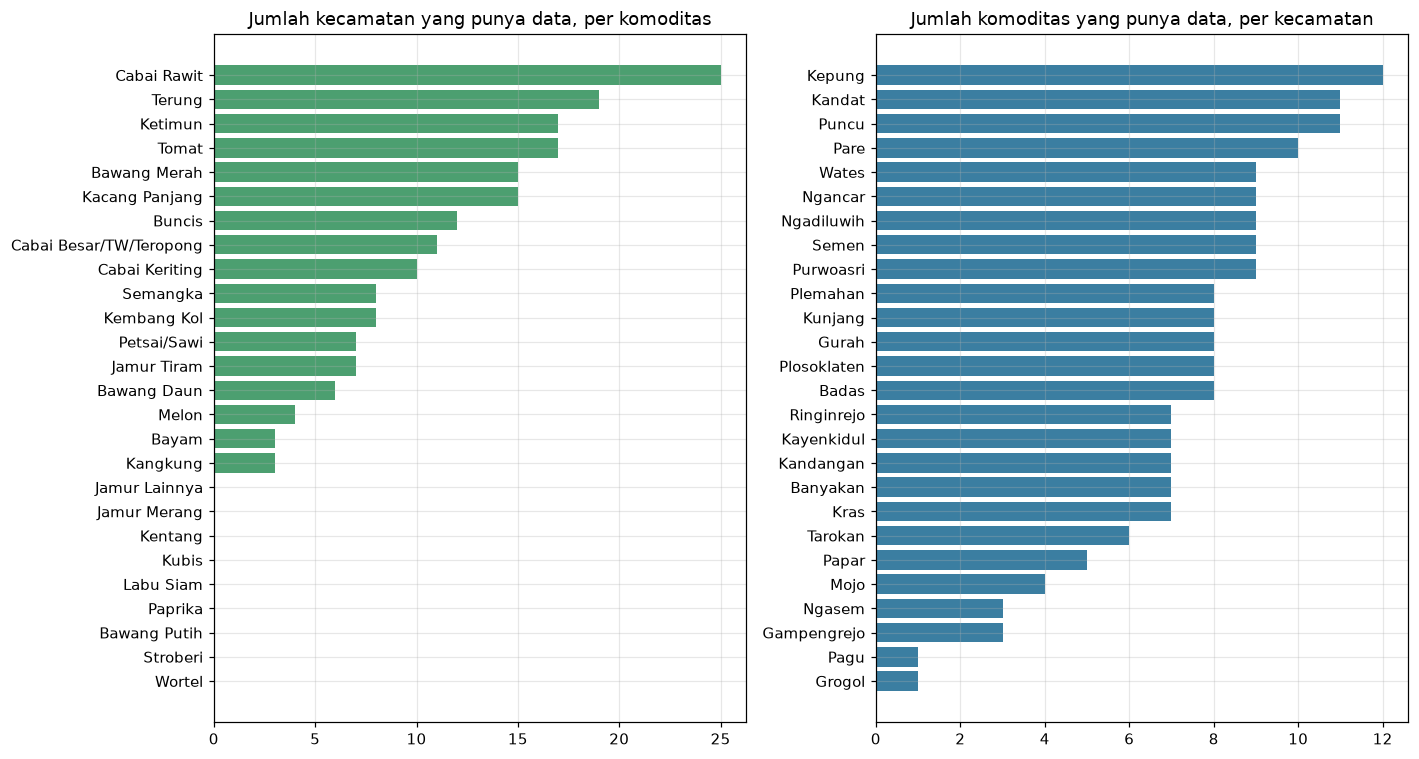

Komoditas TANPA data sama sekali: ['Wortel', 'Stroberi', 'Bawang Putih', 'Paprika', 'Labu Siam', 'Kubis', 'Kentang', 'Jamur Merang', 'Jamur Lainnya']
Kecamatan TANPA data sama sekali: []
Kecamatan dengan data paling sedikit: {'Grogol': 1, 'Pagu': 1, 'Gampengrejo': 3, 'Ngasem': 3}


In [6]:
per_kom = df.groupby("komoditas")["ada_data"].sum().sort_values()
per_kec = df.groupby("kecamatan")["ada_data"].sum().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
ax[0].barh(per_kom.index, per_kom.values, color="#4c9f70")
ax[0].set_title("Jumlah kecamatan yang punya data, per komoditas")
ax[1].barh(per_kec.index, per_kec.values, color="#3b7ea1")
ax[1].set_title("Jumlah komoditas yang punya data, per kecamatan")
plt.tight_layout(); plt.show()

print("Komoditas TANPA data sama sekali:", per_kom[per_kom == 0].index.tolist())
print("Kecamatan TANPA data sama sekali:", per_kec[per_kec == 0].index.tolist())
print("Kecamatan dengan data paling sedikit:", per_kec[per_kec > 0].head(4).to_dict())

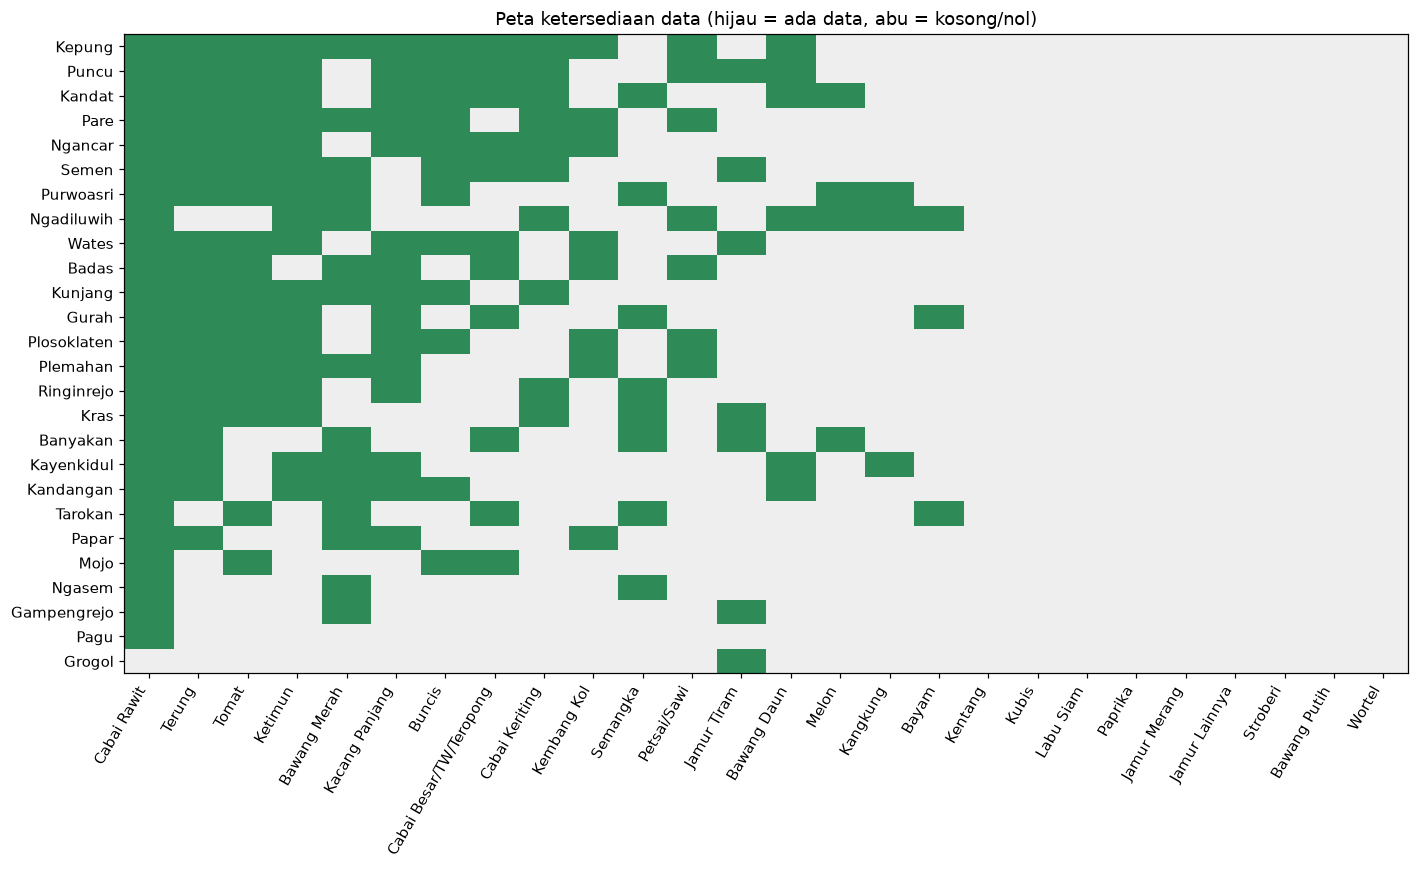

In [7]:
pv = df.pivot_table(index="kecamatan", columns="komoditas", values="ada_data", aggfunc="max").astype(int)
pv = pv.loc[pv.sum(axis=1).sort_values(ascending=False).index, pv.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 8))
ax.imshow(pv.values, cmap=ListedColormap(["#eeeeee", "#2e8b57"]), aspect="auto")
ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns, rotation=60, ha="right")
ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index)
ax.grid(False)
ax.set_title("Peta ketersediaan data (hijau = ada data, abu = kosong/nol)")
plt.tight_layout(); plt.show()

### 5.2 Statistik per komoditas

In [8]:
stat = (d.groupby(["komoditas", "kelompok"])
        .agg(n_kecamatan=("kecamatan", "nunique"),
             total_luas_ha=("luas_ha", "sum"),
             total_produksi_ton=("produksi_ton", "sum"),
             median_produksi_ton=("produksi_ton", "median"),
             median_produktivitas_ku_ha=("produktivitas_ku_ha", "median"))
        .sort_values("total_produksi_ton", ascending=False))
stat

,,n_kecamatan,total_luas_ha,total_produksi_ton,median_produksi_ton,median_produktivitas_ku_ha
komoditas,kelompok,,,,,
Cabai Rawit,Sayuran,25,"9,761.00","109,561.36",886.77,107.37
Cabai Besar/TW/Teropong,Sayuran,11,912.00,"13,743.95",158.20,137.50
Terung,Sayuran,19,337.00,"10,823.54",328.90,256.71
Bawang Merah,Sayuran,15,"1,205.50","8,360.20",108.00,69.11
Tomat,Sayuran,17,368.25,"7,599.94",160.60,194.33
Ketimun,Sayuran,17,330.00,"6,810.93",322.80,171.95
Cabai Keriting,Sayuran,10,340.80,"5,483.43",187.40,95.93
Kacang Panjang,Sayuran,15,419.70,"4,780.65",266.50,109.08
Bawang Daun,Sayuran,6,610.50,"4,426.40",76.15,71.57


**Catatan Jamur Tiram:** luasnya tercatat ±2.948 *Ha* tapi produksinya hanya ±703 ton (produktivitas ±1,9 kuintal/ha, jauh di bawah sayuran lain). Itu tidak masuk akal untuk hektar, kemungkinan satuannya m² atau ukuran lain. **Perlu dikonfirmasi ke yang membersihkan data.** Karena itu jamur dikeluarkan dari analisis luas dan produktivitas.

### 5.3 Komoditas dominan

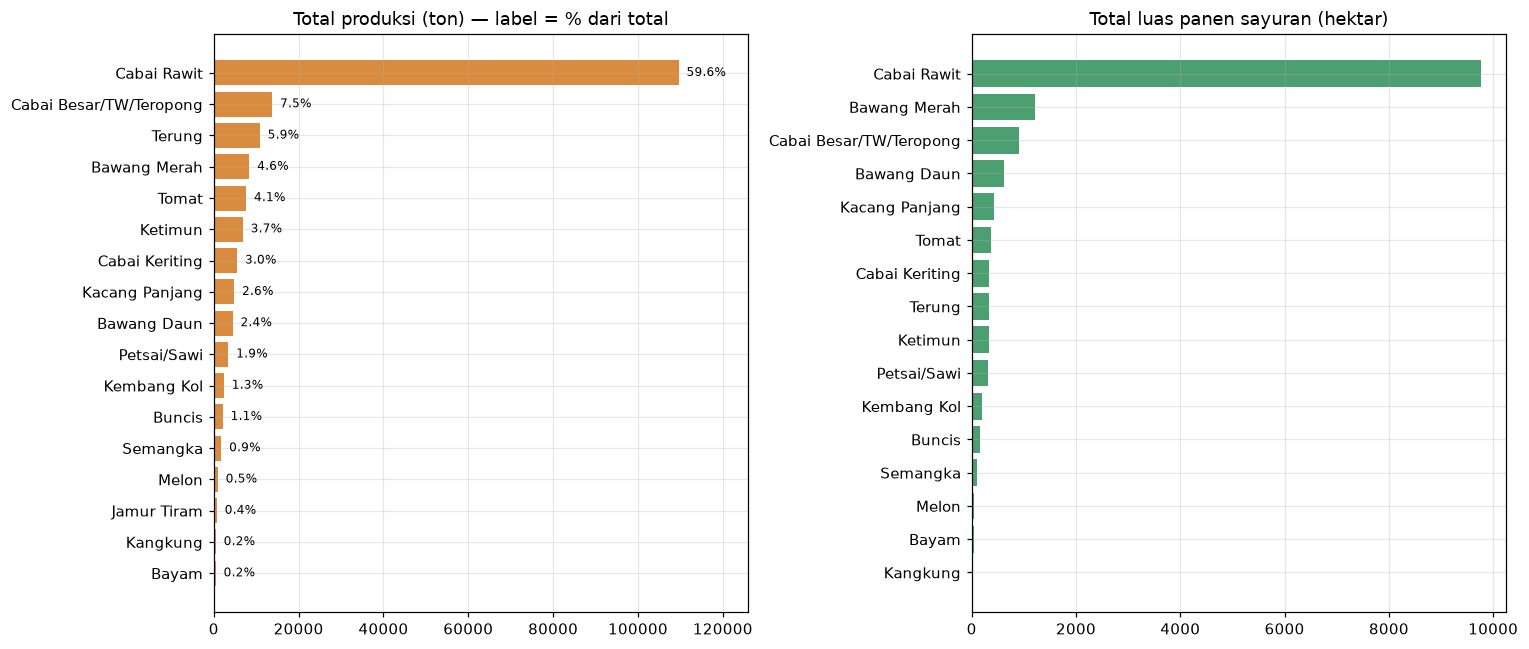

Porsi produksi terbesar: {'Cabai Rawit': 59.6, 'Cabai Besar/TW/Teropong': 7.5, 'Terung': 5.9}
Cabai (rawit + besar + keriting) = 70.1 % dari total produksi


In [9]:
k = d.groupby("komoditas")["produksi_ton"].sum().sort_values()
persen = k / k.sum() * 100
l = sayur.groupby("komoditas")["luas_ha"].sum().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(k.index, k.values, color="#d98c3f")
for y, (v, p) in enumerate(zip(k.values, persen.values)):
    ax[0].text(v, y, f"  {p:.1f}%", va="center", fontsize=8)
ax[0].set_xlim(0, k.max() * 1.15)
ax[0].set_title("Total produksi (ton) — label = % dari total")
ax[1].barh(l.index, l.values, color="#4c9f70")
ax[1].set_title("Total luas panen sayuran (hektar)")
plt.tight_layout(); plt.show()

top = persen.sort_values(ascending=False)
print("Porsi produksi terbesar:", top.head(3).round(1).to_dict())
print("Cabai (rawit + besar + keriting) =", round(persen[[c for c in persen.index if c.lower().startswith("cabai")]].sum(), 1), "% dari total produksi")

### 5.4 Kecamatan penghasil terbesar

,total_produksi_ton,n_komoditas,persen,persen_kumulatif
kecamatan,,,,
Kepung,"35,217.90",12,19.17,19.17
Puncu,"29,357.23",11,15.98,35.15
Pagu,"17,594.30",1,9.58,44.72
Ngancar,"16,657.35",9,9.07,53.79
Wates,"13,667.20",9,7.44,61.23
Plosoklaten,"11,761.32",8,6.40,67.63
Ringinrejo,"10,705.60",7,5.83,73.45
Plemahan,"9,507.45",8,5.17,78.63
Gurah,"8,438.20",8,4.59,83.22


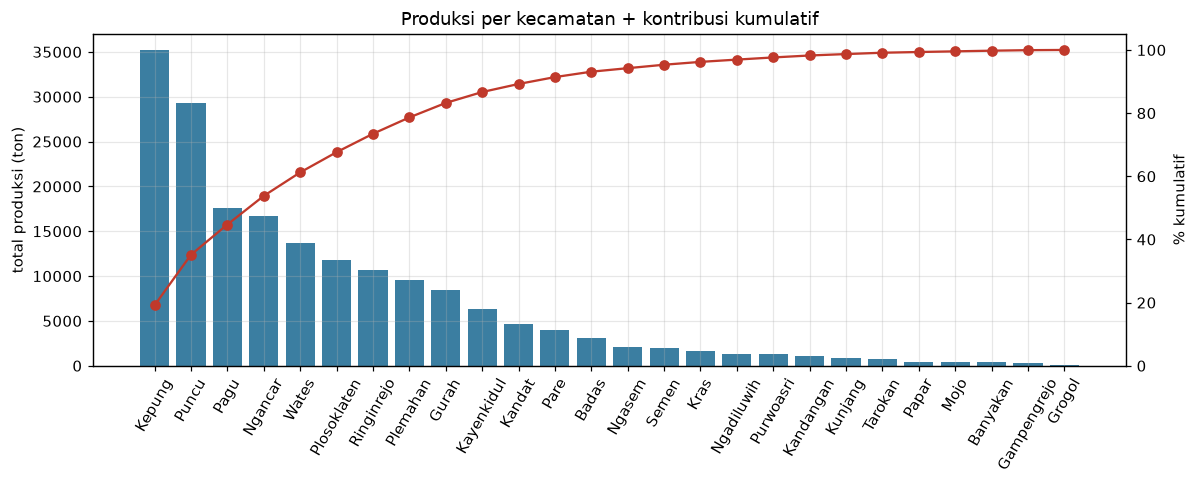

In [10]:
kc = (d.groupby("kecamatan")
      .agg(total_produksi_ton=("produksi_ton", "sum"), n_komoditas=("komoditas", "nunique"))
      .sort_values("total_produksi_ton", ascending=False))
kc["persen"] = kc["total_produksi_ton"] / kc["total_produksi_ton"].sum() * 100
kc["persen_kumulatif"] = kc["persen"].cumsum()
display(kc.head(10))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(kc.index, kc["total_produksi_ton"], color="#3b7ea1")
ax.set_ylabel("total produksi (ton)"); ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.plot(kc.index, kc["persen_kumulatif"], color="#c0392b", marker="o")
ax2.set_ylabel("% kumulatif"); ax2.set_ylim(0, 105); ax2.grid(False)
plt.title("Produksi per kecamatan + kontribusi kumulatif")
plt.tight_layout(); plt.show()

### 5.5 Heatmap produksi: kecamatan × komoditas

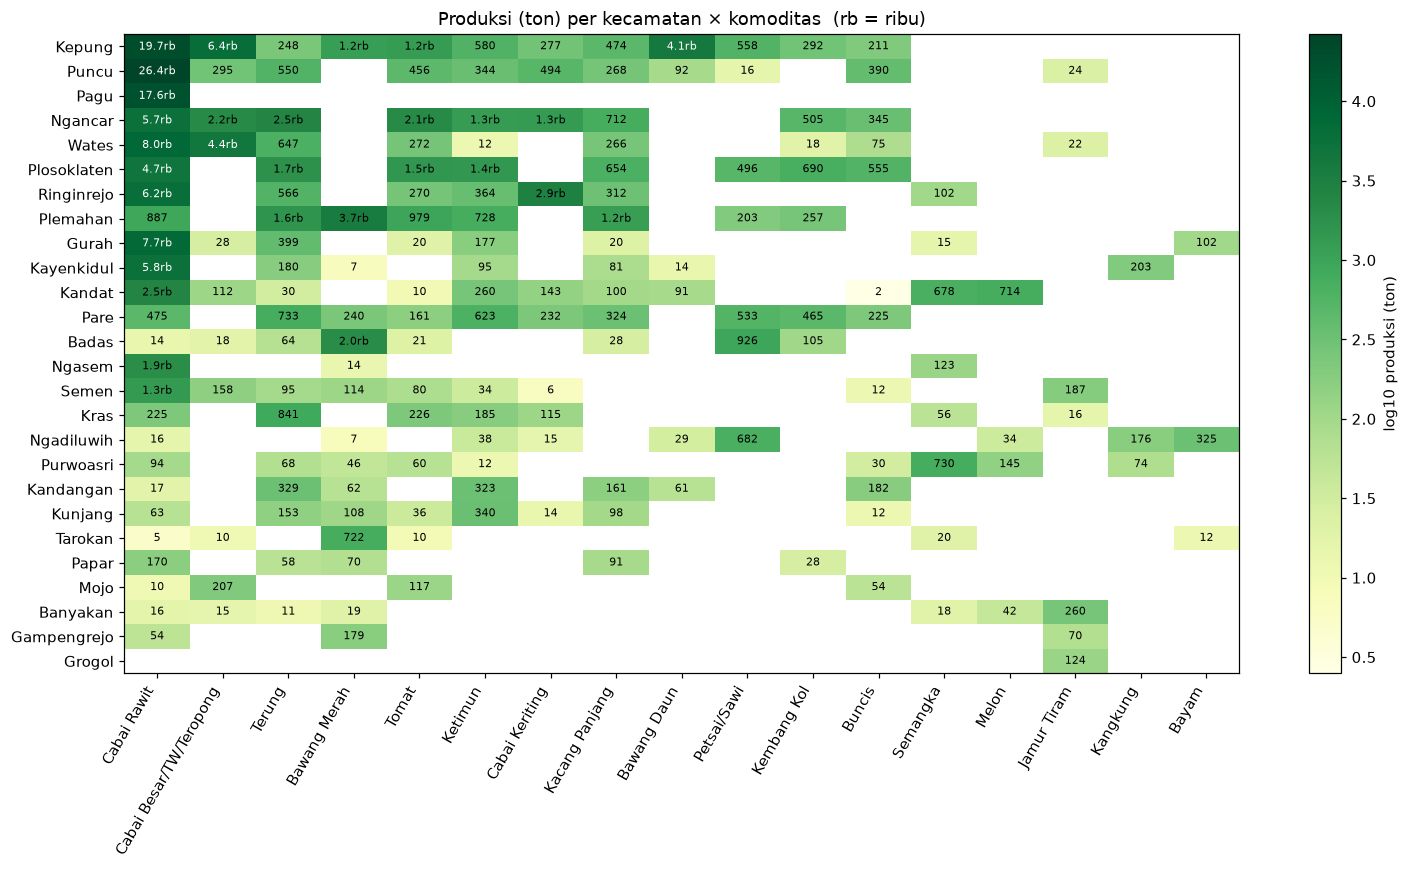

In [11]:
def ringkas(x):
    if pd.isna(x): return ""
    if x >= 1e3: return f"{x/1e3:.1f}rb"
    return f"{x:.0f}"

pvt = d.pivot_table(index="kecamatan", columns="komoditas", values="produksi_ton", aggfunc="sum")
pvt = pvt.loc[pvt.sum(axis=1).sort_values(ascending=False).index, pvt.sum().sort_values(ascending=False).index]
logv = np.log10(pvt)

fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(logv.values, cmap="YlGn", aspect="auto")
for i in range(pvt.shape[0]):
    for j in range(pvt.shape[1]):
        t = ringkas(pvt.iat[i, j])
        if t:
            warna_teks = "white" if logv.iat[i, j] > 3.6 else "black"
            ax.text(j, i, t, ha="center", va="center", fontsize=7, color=warna_teks)
ax.set_xticks(range(pvt.shape[1])); ax.set_xticklabels(pvt.columns, rotation=60, ha="right")
ax.set_yticks(range(pvt.shape[0])); ax.set_yticklabels(pvt.index)
ax.grid(False)
plt.colorbar(im, ax=ax, label="log10 produksi (ton)")
ax.set_title("Produksi (ton) per kecamatan × komoditas  (rb = ribu)")
plt.tight_layout(); plt.show()

### 5.6 Distribusi nilai

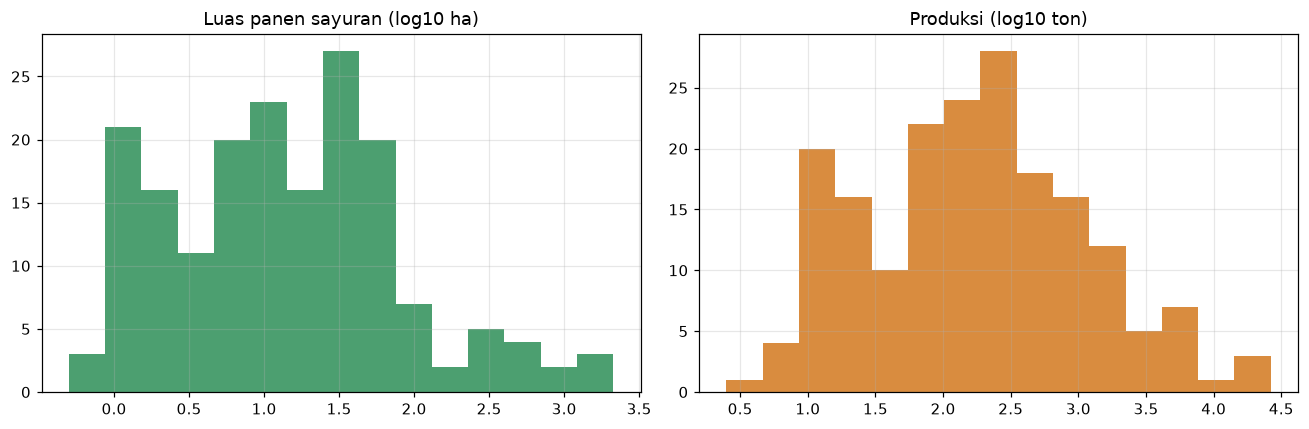

Skewness asli  -> luas: 5.86 | produksi: 6.06
Skewness (log) -> luas: 0.39 | produksi: 0.23


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log10(sayur["luas_ha"]), bins=15, color="#4c9f70")
ax[0].set_title("Luas panen sayuran (log10 ha)")
ax[1].hist(np.log10(d["produksi_ton"]), bins=15, color="#d98c3f")
ax[1].set_title("Produksi (log10 ton)")
plt.tight_layout(); plt.show()

print("Skewness asli  -> luas:", round(sayur["luas_ha"].skew(), 2), "| produksi:", round(d["produksi_ton"].skew(), 2))
print("Skewness (log) -> luas:", round(np.log10(sayur["luas_ha"]).skew(), 2), "| produksi:", round(np.log10(d["produksi_ton"]).skew(), 2))

Sebaran sangat miring ke kanan (sedikit nilai raksasa, banyak nilai kecil), jadi untuk grafik dan model sebaiknya pakai **skala log**.

### 5.7 Hubungan luas panen vs produksi (sayuran)

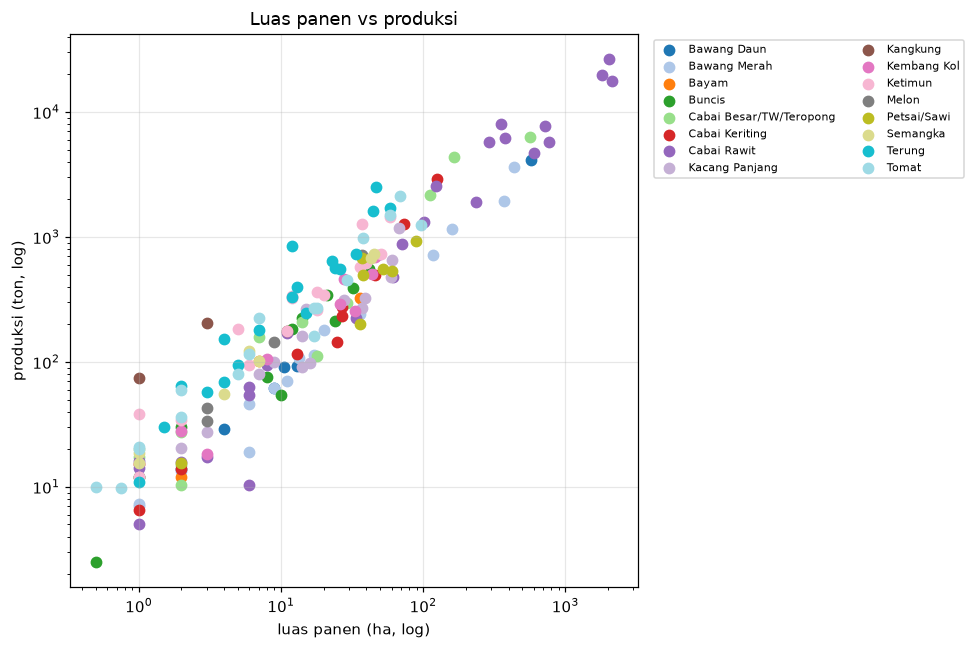

Korelasi Spearman luas vs produksi (sayuran, n=180): 0.947


In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
warna = plt.cm.tab20(np.linspace(0, 1, sayur["komoditas"].nunique()))
for (nama, g), w in zip(sayur.groupby("komoditas"), warna):
    ax.scatter(g["luas_ha"], g["produksi_ton"], label=nama, color=w, s=45)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("luas panen (ha, log)"); ax.set_ylabel("produksi (ton, log)")
ax.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("Luas panen vs produksi")
plt.tight_layout(); plt.show()

rho = sayur["luas_ha"].corr(sayur["produksi_ton"], method="spearman")
print(f"Korelasi Spearman luas vs produksi (sayuran, n={len(sayur)}): {rho:.3f}")

### 5.8 Produktivitas per komoditas (kuintal/ha)

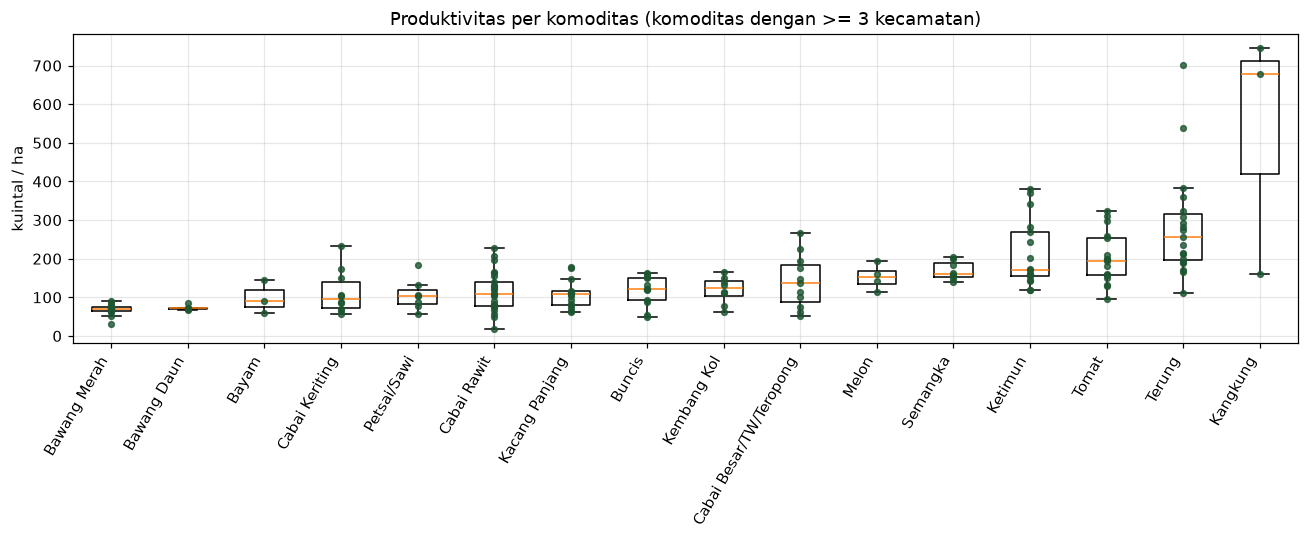

Komoditas dengan < 3 kecamatan (tidak ditampilkan): {}


In [14]:
n_per_kom = sayur.groupby("komoditas")["produktivitas_ku_ha"].count()
kom_ok = n_per_kom[n_per_kom >= 3].index
urut = sayur[sayur["komoditas"].isin(kom_ok)].groupby("komoditas")["produktivitas_ku_ha"].median().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([sayur.loc[sayur["komoditas"] == n, "produktivitas_ku_ha"].values for n in urut], showfliers=False)
for i, n in enumerate(urut, start=1):
    v = sayur.loc[sayur["komoditas"] == n, "produktivitas_ku_ha"].values
    ax.scatter(np.full(len(v), i), v, color="#1e5631", s=14, alpha=.8, zorder=3)
ax.set_xticks(range(1, len(urut) + 1)); ax.set_xticklabels(urut, rotation=60, ha="right")
ax.set_ylabel("kuintal / ha")
ax.set_title("Produktivitas per komoditas (komoditas dengan >= 3 kecamatan)")
plt.tight_layout(); plt.show()
print("Komoditas dengan < 3 kecamatan (tidak ditampilkan):", n_per_kom[n_per_kom < 3].to_dict())

In [15]:
# Tandai produktivitas yang jauh dari median komoditasnya (perlu dicek, bukan otomatis salah)
sayur["median_kom"] = sayur.groupby("komoditas")["produktivitas_ku_ha"].transform("median")
sayur["n_kom"] = sayur.groupby("komoditas")["produktivitas_ku_ha"].transform("count")
sayur["rasio_median"] = sayur["produktivitas_ku_ha"] / sayur["median_kom"]

curiga = sayur[(sayur["n_kom"] >= 3) & ((sayur["rasio_median"] > 2.5) | (sayur["rasio_median"] < 0.4))]
print("Jumlah baris yang ditandai:", len(curiga))
curiga[["kecamatan", "komoditas", "luas_ha", "produksi_ton", "produktivitas_ku_ha", "rasio_median"]].sort_values("rasio_median", ascending=False)

Jumlah baris yang ditandai: 4


,kecamatan,komoditas,luas_ha,produksi_ton,produktivitas_ku_ha,rasio_median
607,Kras,Terung,12.00,841.20,701.00,2.73
154,Tarokan,Cabai Besar/TW/Teropong,2.00,10.40,52.00,0.38
324,Ngadiluwih,Kangkung,11.00,175.70,159.73,0.24
193,Mojo,Cabai Rawit,6.00,10.40,17.33,0.16


## 6. Kesiapan untuk Pemodelan

Sebelum memilih model, dicek dulu: **berapa banyak data yang benar-benar bisa dipakai**, dan **seberapa jauh luas panen saja sudah bisa menebak produksi?**

In [20]:
n_per = sayur.groupby("komoditas").size().sort_values(ascending=False)
print("Jumlah baris berdata (sayuran):", len(sayur))
print("Komoditas dengan >= 10 baris :", n_per[n_per >= 10].index.tolist())
print("Komoditas dengan 5-9 baris   :", n_per[(n_per >= 5) & (n_per < 10)].index.tolist())
print("Komoditas dengan < 5 baris   :", n_per[n_per < 5].index.tolist())

Jumlah baris berdata (sayuran): 180
Komoditas dengan >= 10 baris : ['Cabai Rawit', 'Terung', 'Ketimun', 'Tomat', 'Bawang Merah', 'Kacang Panjang', 'Buncis', 'Cabai Besar/TW/Teropong', 'Cabai Keriting']
Komoditas dengan 5-9 baris   : ['Kembang Kol', 'Semangka', 'Petsai/Sawi', 'Bawang Daun']
Komoditas dengan < 5 baris   : ['Melon', 'Bayam', 'Kangkung']


In [17]:
# Uji cepat (baseline): tebak produksi = luas panen x produktivitas median komoditas itu.
# Validasi "tinggalkan satu kecamatan": tiap kecamatan diuji memakai data dari kecamatan LAIN.
b = sayur[["kecamatan", "komoditas", "luas_ha", "produksi_ton"]].copy()
b["pred_luas"] = np.nan      # model: luas x median produktivitas
b["pred_median"] = np.nan    # pembanding: median produksi komoditas (tanpa luas)

for kec in b["kecamatan"].unique():
    latih = b[b["kecamatan"] != kec]
    uji = b["kecamatan"] == kec
    ton_per_ha = (latih["produksi_ton"] / latih["luas_ha"]).groupby(latih["komoditas"]).median()
    med_prod = latih.groupby("komoditas")["produksi_ton"].median()
    b.loc[uji, "pred_luas"] = b.loc[uji, "komoditas"].map(ton_per_ha) * b.loc[uji, "luas_ha"]
    b.loc[uji, "pred_median"] = b.loc[uji, "komoditas"].map(med_prod)

ok = b.dropna(subset=["pred_luas", "pred_median"])
print(f"Baris yang bisa diuji: {len(ok)} dari {len(b)}")
if len(ok) < len(b):
    print("(sisanya komoditas yang hanya ada di 1 kecamatan, jadi tidak ada data pembanding)")
print()

def metrik(y, p):
    mae = (y - p).abs().mean()
    mape = ((y - p).abs() / y).mean() * 100
    r2 = 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    r2_log = 1 - ((np.log10(y) - np.log10(p)) ** 2).sum() / ((np.log10(y) - np.log10(y).mean()) ** 2).sum()
    return pd.Series({"MAE (ton)": mae, "MAPE (%)": mape, "R2": r2, "R2 (log)": r2_log})

hasil = pd.DataFrame({
    "luas x median produktivitas": metrik(ok["produksi_ton"], ok["pred_luas"]),
    "median produksi saja (tanpa luas)": metrik(ok["produksi_ton"], ok["pred_median"]),
}).T
hasil

Baris yang bisa diuji: 180 dari 180



,MAE (ton),MAPE (%),R2,R2 (log)
luas x median produktivitas,272.90,36.56,0.93,0.95
median produksi saja (tanpa luas),983.79,730.37,-0.02,-0.12


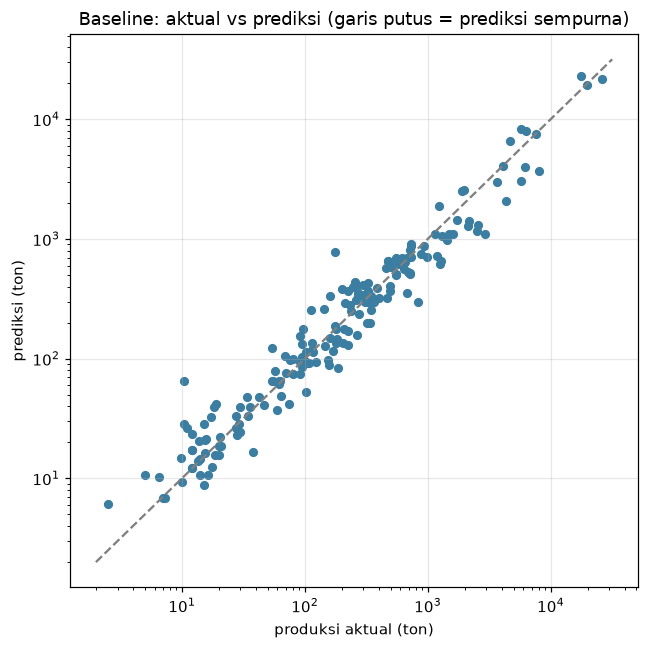

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(ok["produksi_ton"], ok["pred_luas"], s=25, color="#3b7ea1")
lim = [ok[["produksi_ton", "pred_luas"]].min().min() * 0.8, ok[["produksi_ton", "pred_luas"]].max().max() * 1.2]
ax.plot(lim, lim, "--", color="gray")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("produksi aktual (ton)"); ax.set_ylabel("prediksi (ton)")
ax.set_title("Baseline: aktual vs prediksi (garis putus = prediksi sempurna)")
plt.tight_layout(); plt.show()

**Cara membaca:** model paling sederhana (luas × produktivitas median) dibandingkan dengan tebakan tanpa luas. Kalau yang pertama jauh lebih baik, berarti **luas panen adalah fitur terkuat**. Model yang lebih rumit nanti harus mengalahkan angka baseline ini, kalau tidak, tidak perlu dipakai.

## 7. Kesimpulan

**Kualitas data**
- Kedua file konsisten: 26 kecamatan × 26 komoditas = 676 baris, tanpa nilai kosong atau duplikat. Luas = 0 selalu bersamaan dengan produksi = 0.
- Hanya **187 dari 676 baris (27,7%)** yang berisi data (180 sayuran + 7 jamur tiram). Sisanya bernilai 0 (tidak ada panen / tidak tercatat).
- **9 komoditas tidak punya data sama sekali**: Bawang Putih, Kentang, Jamur Merang, Jamur Lainnya, Stroberi, Paprika, Labu Siam, Kubis, Wortel. Semua 26 kecamatan punya minimal satu komoditas.
- Perlu dikonfirmasi: satuan luas **Jamur Tiram** (tercatat Ha tapi tidak masuk akal) dan 4 baris produktivitas yang ekstrem.

**Isi data**
- **Cabai Rawit mendominasi**: ±60% total produksi (±70% kalau semua jenis cabai dihitung).
- Produksi terpusat di sedikit kecamatan: **Kepung (19%)**, **Puncu (16%)**, dan **Pagu (10%, hanya dari cabai rawit)**. Lima kecamatan teratas ±61% dari total.
- Luas panen dan produksi sangat berkaitan (korelasi Spearman ±0,95).
- Sebaran nilai sangat miring ke kanan, jadi pakai **skala log** untuk grafik dan model.

**Kesiapan untuk model**
- Data sayuran yang bisa dipakai hanya **180 baris**. Cuma 9 komoditas yang punya ≥10 baris, dan 3 komoditas punya <5 baris (Melon, Bayam, Kangkung).
- Baseline sederhana (luas × produktivitas median komoditas, divalidasi per kecamatan) sudah memberi **R² ±0,93 (skala log ±0,95)** dan **MAPE ±37%**, sedangkan tebakan tanpa luas panen R² ≈ 0. Jadi **luas panen adalah fitur terkuat**. Catatan: R² dalam ton banyak dipengaruhi cabai rawit yang nilainya besar.
- Data **tidak punya kolom tahun/periode**, jadi **forecast time series (ARIMA, Exponential Smoothing, Prophet) belum bisa dibuat**. Yang bisa: model lintas wilayah (prediksi produksi dari luas, komoditas, dll.) dan clustering kecamatan.

**Langkah berikutnya**
1. Konfirmasi ke yang membersihkan data: apakah ada versi multi-tahun, dan satuan luas Jamur Tiram.
2. Model yang layak dicoba: regresi `log(produksi) ~ log(luas) + komoditas` sebagai model utama, lalu Random Forest / Gradient Boosting sebagai pembanding. Evaluasi per kecamatan, dan harus mengalahkan angka baseline di atas.
3. Lanjut EDA data buah dan gabungkan dengan sayur.

## 8. Simpan Data Hasil Olahan

In [19]:
df.to_csv(os.path.join(OUT_HORTI, "sayur_kecamatan_gabungan.csv"), index=False)
d.to_csv(os.path.join(OUT_HORTI, "sayur_kecamatan_ada_data.csv"), index=False)

print("Tersimpan di:", OUT_HORTI)
for f in sorted(os.listdir(OUT_HORTI)):
    if f.endswith(".csv"):
        print(" -", f, f"({len(pd.read_csv(os.path.join(OUT_HORTI, f)))} baris)")

Tersimpan di: c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\processed\hortikultura
 - sayur_kecamatan_ada_data.csv (187 baris)
 - sayur_kecamatan_gabungan.csv (676 baris)
